# Elements vs plasma proteome (ART macaques)
Within-animal analysis (each animal = own baseline, permutation p-values, all samples kept, Ni ignored).
**Model:** protein ~ element + log10 viral load (VL stands in for ART time). Run all; upload the 3 files when asked.

In [1]:
import sys, os, re, warnings, shutil, time
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
B_PERM, B_LOAO, K_TOP = 500, 200, 100
DATA_DIR = os.environ.get("DATA_DIR", "/content"); OUT = "results"; os.makedirs(OUT, exist_ok=True)
ELEMENTS = ["Na", "Mg", "P", "K", "Ca", "Fe", "Cu", "Zn"]
RATIOS = {"Cu/Zn": ("Cu", "Zn"), "Fe/Cu": ("Fe", "Cu"), "Fe/Zn": ("Fe", "Zn"), "Na/K": ("Na", "K"), "Ca/Mg": ("Ca", "Mg"), "Ca/P": ("Ca", "P")}
STAGES = ["Pre-ART", "Early-ART", "Mid-ART", "Late-ART"]
BLUE, ORANGE, GREY, NAVY = "#2a78d6", "#eb6834", "#c5c4be", "#0b3f7e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 100, "font.size": 9})
zs = lambda v: (np.asarray(v, float) - np.mean(v)) / np.std(v, ddof=1)
def bh(p):
    p = np.asarray(p, float); o = np.argsort(p); r = p[o] * len(p) / (np.arange(len(p)) + 1); r = np.minimum.accumulate(r[::-1])[::-1]; q = np.empty_like(p); q[o] = np.minimum(r, 1); return q
need = ["Cleaned_data.xlsx", "SomaExpr_common.csv", "sample_metadata.tsv"]
if "google.colab" in sys.modules and not all(os.path.exists(f"{DATA_DIR}/{f}") for f in need):
    from google.colab import files; files.upload()

## 0. Data

In [2]:
xl = pd.read_excel(f"{DATA_DIR}/Cleaned_data.xlsx"); xl = xl.loc[:, ~xl.columns.astype(str).str.startswith("Unnamed")]; xl.columns = [str(c).strip() for c in xl.columns]
def sid(n):
    m = re.match(r"^(\w+)\s+\S+\s+wk(\d+)\s*$", str(n).strip()); return f"{m.group(1)}_{m.group(2)}" if m else None
xl["ID"] = xl["Sample Name"].map(sid); xl = xl[~xl["Sample Name"].str.contains("Naive", case=False)].set_index("ID")
meta = pd.read_csv(f"{DATA_DIR}/sample_metadata.tsv", sep="\t").set_index("nhp_week_index")
meta["VL"] = np.log10(meta["viral_load"].fillna(50).clip(lower=50))
s = pd.read_csv(f"{DATA_DIR}/SomaExpr_common.csv", index_col=0); samples = [c for c in s.columns if re.match(r"^[A-Za-z0-9]+_\d+$", c)]
s = s[s["Type_meta"] == "Protein"] if "Type_meta" in s else s
ann = s[["Target", "EntrezGeneSymbol"]].copy(); ann["label"] = ann["EntrezGeneSymbol"].fillna(pd.Series(s.index, s.index)).astype(str)
Y = np.log2(s[samples] + 1).T
d = xl.loc[samples, ELEMENTS].join(meta[["nhp_id", "ART_stage", "VL"]]); d["week"] = [int(i.rsplit("_", 1)[1]) for i in d.index]
for k, (a, b) in RATIOS.items(): d[k] = np.log2(d[a] / d[b])
print(f"{len(d)} samples | {d.nhp_id.nunique()} animals | {Y.shape[1]} proteins")
display(pd.crosstab(d.nhp_id, d.ART_stage.astype(pd.CategoricalDtype(STAGES, ordered=True))))

27 samples | 8 animals | 11011 proteins


ART_stage,Pre-ART,Early-ART,Mid-ART,Late-ART
nhp_id,,,,
DEAB,1,2,0,1
DEL5,1,2,1,1
GA43,0,2,1,1
KPN,1,0,0,0
T530,1,0,0,0
T544,1,1,2,2
T545,1,0,0,0
T623,1,1,0,3


In [3]:
class Within:
    def __init__(self, d, Y):
        cnt = d.nhp_id.value_counts(); keep = d.nhp_id.isin(cnt[cnt >= 2].index).values; self.idx = np.where(keep)[0]
        self.d = d.iloc[self.idx]; self.animal = self.d.nhp_id.values; self.N = len(self.idx); self.groups = sorted(set(self.animal))
        self.members = {a: np.where(self.animal == a)[0] for a in self.groups}; self.cols = Y.columns
        self.Yw = self.demean(Y.values[keep]); t = np.log2(self.d.week.values + 1.0); t = zs(t); self.T = np.column_stack([self.demean(t[:, None]), self.demean((t ** 2)[:, None])])
    def demean(self, M):
        M = np.asarray(M, float).copy()
        for r in self.members.values(): M[r] -= M[r].mean(0)
        return M
    def shuffle(self, v, rng):
        o = v.copy()
        for r in self.members.values(): o[r] = rng.permutation(v[r])
        return o
    def fit(self, e, vl):
        X = np.column_stack([self.demean(zs(e)[:, None])[:, 0], self.demean(zs(vl)[:, None])[:, 0]]); G = np.linalg.inv(X.T @ X); XtY = X.T @ self.Yw
        b = G @ XtY; rss = (self.Yw ** 2).sum(0) - (b * XtY).sum(0); s2 = rss / (self.N - len(self.groups) - 2); return b, b / np.sqrt(np.outer(np.diag(G), s2))
    def scan1(self, v, B, sets, seed):
        v = np.asarray(v)[self.idx]; rng = np.random.default_rng(seed); F = self.Yw.shape[1]
        def f1(x):
            xw = self.demean(zs(x)[:, None])[:, 0]; b = xw @ self.Yw / (xw @ xw); rss = (self.Yw ** 2).sum(0) - b ** 2 * (xw @ xw); return b, b / np.sqrt(rss / (self.N - len(self.groups) - 1) / (xw @ xw))
        b0, t0 = f1(v); Wm = np.zeros((len(sets), F))
        for i, k in enumerate(sets): Wm[i, sets[k]] = 1 / len(sets[k])
        nt = np.empty((B, F), np.float32); m2 = []
        for k in range(B): _, t = f1(self.shuffle(v, rng)); nt[k] = np.abs(t); m2.append(Wm @ t ** 2)
        ns = np.sort(nt.ravel()); p = (1 + len(ns) - np.searchsorted(ns, np.abs(t0), side="left")) / (1 + len(ns)); o2 = Wm @ t0 ** 2
        res = pd.DataFrame({"feature": self.cols, "label": ann.loc[self.cols, "label"].values, "slope_E": b0, "t_E": t0, "p_E": p}); res["q_E"] = bh(p)
        return res, pd.DataFrame({"group": list(sets), "n": [len(x) for x in sets.values()], "p_set_E": (1 + (np.array(m2) >= o2).sum(0)) / (1 + B)})
    def scan(self, e, vl, B, sets, seed):
        e, vl = np.asarray(e)[self.idx], np.asarray(vl)[self.idx]; rng = np.random.default_rng(seed); b0, t0 = self.fit(e, vl); F = t0.shape[1]
        Wm = np.zeros((len(sets), F))
        for i, k in enumerate(sets): Wm[i, sets[k]] = 1 / len(sets[k])
        out, sres = {}, {}
        for term, tag in [(0, "E"), (1, "VL")]:
            nt = np.empty((B, F), np.float32); m2 = []
            for k in range(B):
                _, t = self.fit(self.shuffle(e, rng), vl) if term == 0 else self.fit(e, self.shuffle(vl, rng)); nt[k] = np.abs(t[term]); m2.append(Wm @ t[term] ** 2)
            ns = np.sort(nt.ravel()); out[tag] = (1 + len(ns) - np.searchsorted(ns, np.abs(t0[term]), side="left")) / (1 + len(ns))
            o2 = Wm @ t0[term] ** 2; sres[tag] = (1 + (np.array(m2) >= o2).sum(0)) / (1 + B)
        res = pd.DataFrame({"feature": self.cols, "label": ann.loc[self.cols, "label"].values, "slope_E": b0[0], "t_E": t0[0], "p_E": out["E"], "slope_VL": b0[1], "t_VL": t0[1], "p_VL": out["VL"]})
        res["q_E"], res["q_VL"] = bh(res.p_E.values), bh(res.p_VL.values)
        return res, pd.DataFrame({"group": list(sets), "n": [len(v) for v in sets.values()], "p_set_E": sres["E"], "p_set_VL": sres["VL"]})
W = Within(d, Y); print(f"usable for within-animal tests: {W.N} samples, {len(W.groups)} animals")

usable for within-animal tests: 24 samples, 5 animals


In [4]:
KNOWN = {
 "Iron": ["TF", "TFRC", "FTL", "FTH1", "HP", "HPX", "LTF", "HAMP", "LCN2", "HMOX1", "TFR2", "CP"],
 "Copper": ["CP", "SOD1", "SOD3", "ATOX1", "CCS", "LOXL2", "AOC3", "APP", "MT2A"],
 "Zinc": ["ALB", "MT1A", "MT2A", "CA1", "CA2", "MMP2", "MMP9", "ADAM10", "ADAM17", "S100A8", "S100A9", "S100A12"],
 "Calcium/bone": ["CALM1", "CALR", "GSN", "PTH", "CALCA", "BGLAP", "SPP1", "FGF23", "KL", "ANXA1", "ANXA2", "ANXA5", "PROS1", "F2"],
 "Na/K transport": ["ATP1A1", "ATP1B1", "ATP1B2", "ATP1B3", "FXYD2", "ATP2B1", "ATP2B4"],
 "Acute phase": ["CRP", "SAA1", "SAA2", "ORM1", "SERPINA1", "SERPINA3", "LBP", "IL6", "IL1B", "TNF", "FGA", "FGB", "FGG", "A2M"],
 "Interferon": ["ISG15", "MX1", "IFIT1", "IFIT3", "OAS1", "IFI6", "IRF7", "STAT1", "CXCL10", "IFI27", "RSAD2"],
 "Platelet": ["PF4", "PPBP", "GP1BA", "GP1BB", "GP9", "ITGA2B", "ITGB3", "SELP", "THBS1", "TUBB1", "CD9", "MYL9", "MYL12A", "FLNA"],
 "Red cell": ["HBB", "HBD", "HBA1", "CAT", "BLVRB", "FECH", "ALAS2", "G6PD", "PRDX2", "SLC4A1"]}
lab = ann.label.values; SETS = {g: np.where(np.isin(lab, v))[0] for g, v in KNOWN.items()}; SETS = {g: i for g, i in SETS.items() if len(i) >= 3}
print({g: len(i) for g, i in SETS.items()})
CACHE = {}
def run(name):
    if name not in CACHE:
        t0 = time.time(); CACHE[name] = W.scan1(d.VL.values, B_PERM, SETS, seed=1) if name == "VL" else W.scan(d[name].values, d.VL.values, B_PERM, SETS, seed=sum(map(ord, name))); r = CACHE[name][0]
        r.to_csv(f"{OUT}/scan_{name.replace('/', '_')}.csv", index=False); print(f"{name}: {time.time()-t0:.0f}s")
    return CACHE[name]

{'Iron': 17, 'Copper': 9, 'Zinc': 15, 'Calcium/bone': 19, 'Na/K transport': 5, 'Acute phase': 16, 'Interferon': 12, 'Platelet': 18, 'Red cell': 8}


In [5]:
def volcano(ax, r, tag, title):
    x, y = r[f"slope_{tag}"], -np.log10(r[f"p_{tag}"]); q = r[f"q_{tag}"] < .10; n = r[f"p_{tag}"] < .001
    ax.scatter(x[~n], y[~n], s=4, c=GREY); ax.scatter(x[n & ~q], y[n & ~q], s=9, c=BLUE); ax.scatter(x[q], y[q], s=14, c=ORANGE)
    for i in r[f"p_{tag}"].nsmallest(5).index: ax.annotate(r.label[i][:10], (x[i], y[i]), fontsize=7, xytext=(2, 2), textcoords="offset points")
    ax.set_title(f"{title}\nFDR<0.10: {int(q.sum())} | p<0.001: {int(n.sum())}", fontsize=9); ax.set_xlabel("slope (log2 protein / SD)"); ax.set_ylabel("-log10 p")
def counts(r):
    rows = []
    for nm, fe, fv in [("FDR<0.10", r.q_E < .10, r.q_VL < .10), ("p<0.001", r.p_E < .001, r.p_VL < .001), ("p<0.01", r.p_E < .01, r.p_VL < .01)]:
        rows.append({"threshold": nm, "element only": int((fe & ~fv).sum()), "VL only": int((~fe & fv).sum()), "both": int((fe & fv).sum()), "both expected if independent": round(fe.sum() * fv.sum() / len(r), 1)})
    return pd.DataFrame(rows)
def three_panel(name):
    r, st = run(name); fig, ax = plt.subplots(1, 3, figsize=(15, 3.9)); volcano(ax[0], r, "E", f"{name}"); volcano(ax[1], r, "VL", "viral load (adjusted for " + name + ")")
    eo, vo, bo = (r.p_E < .01) & ~(r.p_VL < .01), ~(r.p_E < .01) & (r.p_VL < .01), (r.p_E < .01) & (r.p_VL < .01)
    ax[2].scatter(r.t_E[~(eo | vo | bo)], r.t_VL[~(eo | vo | bo)], s=4, c=GREY); ax[2].scatter(r.t_E[eo], r.t_VL[eo], s=8, c=BLUE, label=f"{name} only ({eo.sum()})"); ax[2].scatter(r.t_E[vo], r.t_VL[vo], s=8, c=ORANGE, label=f"VL only ({vo.sum()})"); ax[2].scatter(r.t_E[bo], r.t_VL[bo], s=22, c=NAVY, label=f"both ({bo.sum()})")
    ax[2].axhline(0, c="k", lw=.5); ax[2].axvline(0, c="k", lw=.5); ax[2].set_xlabel(f"t ({name})"); ax[2].set_ylabel("t (viral load)"); ax[2].legend(fontsize=7, frameon=False); ax[2].set_title("p<0.01 in each term", fontsize=9)
    fig.tight_layout(); plt.show(); display(counts(r).set_index("threshold"))

## 1. Elements: element / viral load / both

Na: 3s


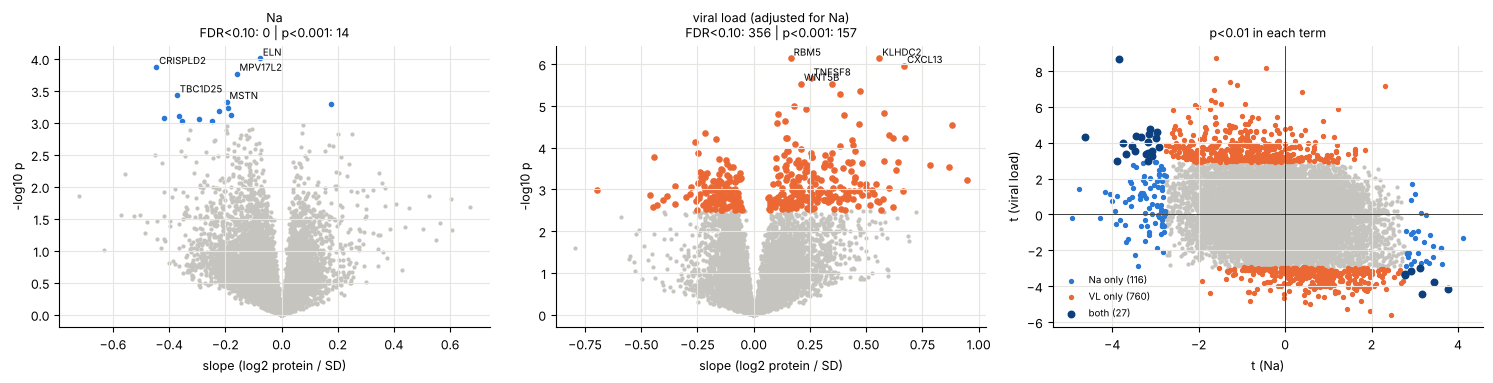

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,0,356,0,0.0
p<0.001,12,155,2,0.2
p<0.01,116,760,27,10.2


Mg: 3s


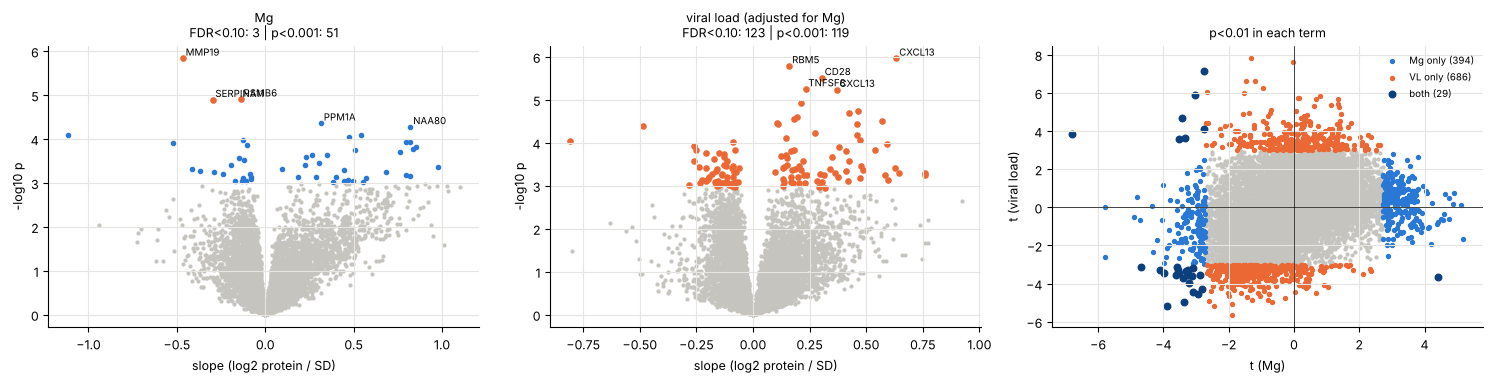

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,3,123,0,0.0
p<0.001,50,118,1,0.6
p<0.01,394,686,29,27.5


P: 3s


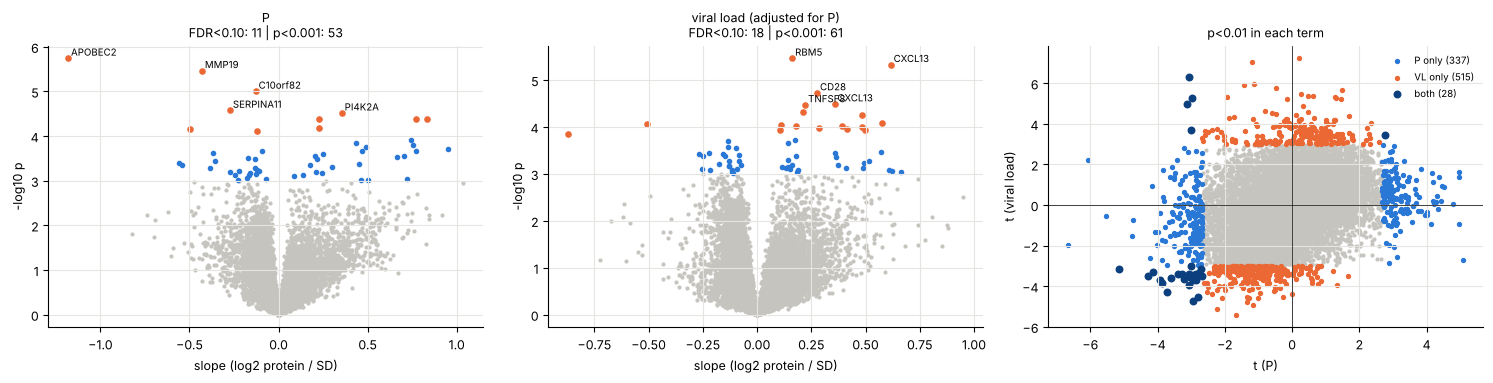

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,11,18,0,0.0
p<0.001,52,60,1,0.3
p<0.01,337,515,28,18.0


K: 3s


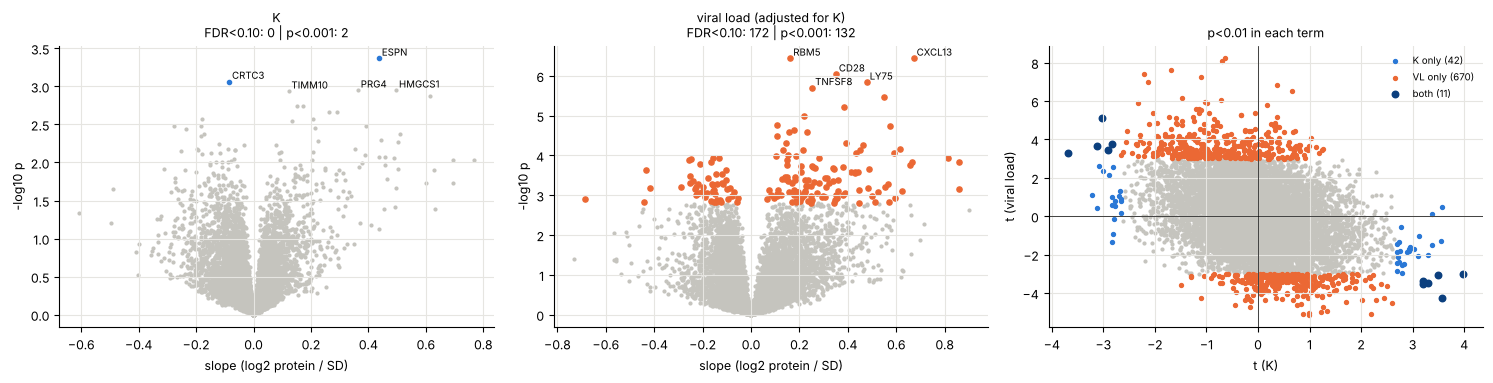

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,0,172,0,0.0
p<0.001,2,132,0,0.0
p<0.01,42,670,11,3.3


Ca: 2s


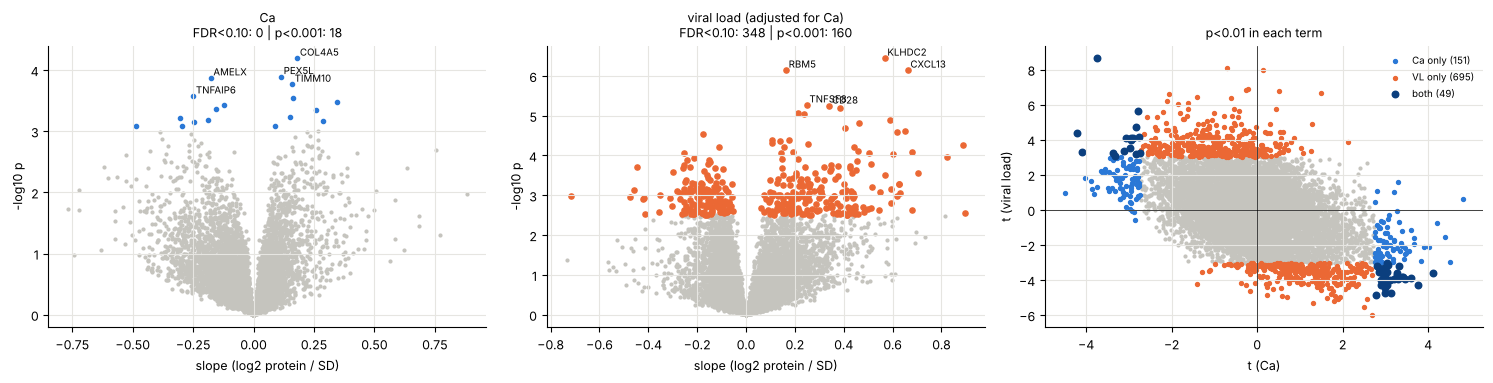

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,0,348,0,0.0
p<0.001,15,157,3,0.3
p<0.01,151,695,49,13.5


Fe: 2s


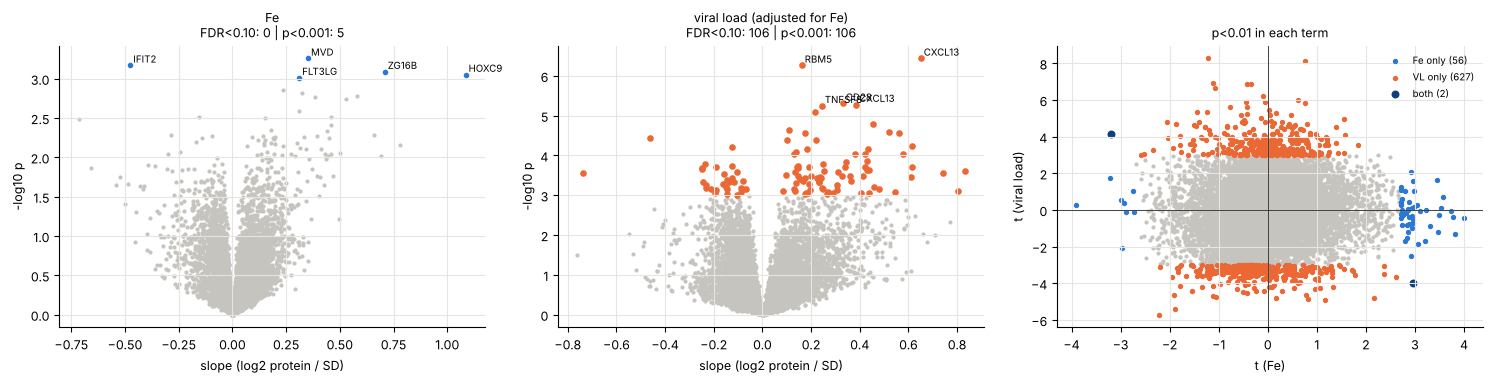

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,0,106,0,0.0
p<0.001,5,106,0,0.0
p<0.01,56,627,2,3.3


Cu: 2s


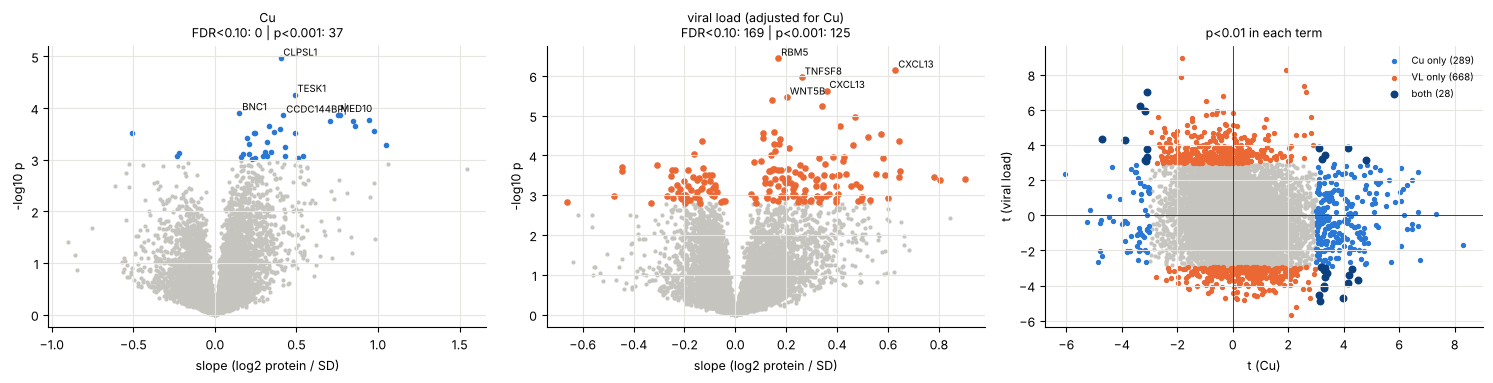

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,0,169,0,0.0
p<0.001,37,125,0,0.4
p<0.01,289,668,28,20.0


Zn: 2s


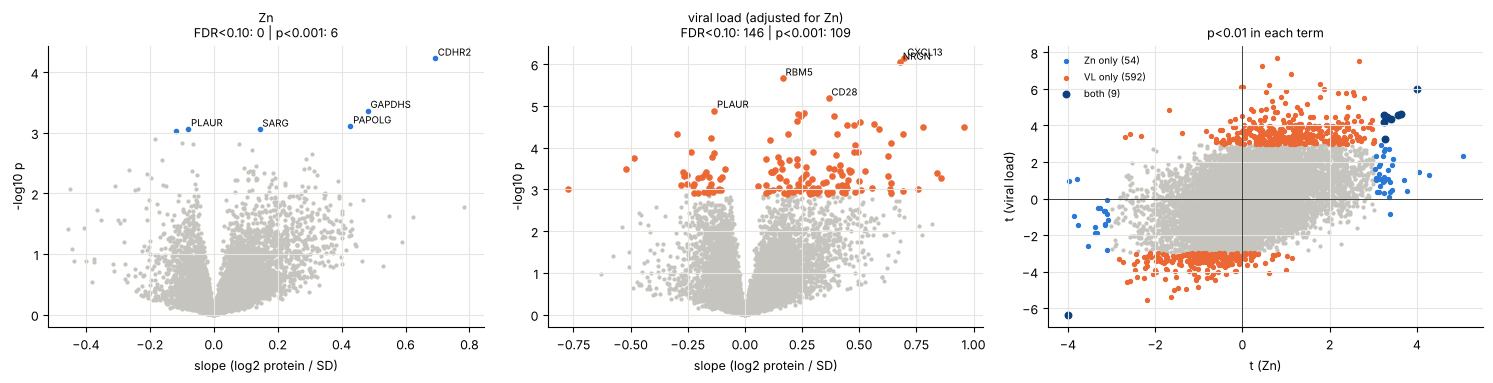

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,0,146,0,0.0
p<0.001,4,107,2,0.1
p<0.01,54,592,9,3.4


In [6]:
for el in ELEMENTS: three_panel(el)

In [7]:
rows = []
for el in ELEMENTS:
    r = CACHE[el][0]; rows.append({"element": el, "FDR<0.10 element": int((r.q_E < .1).sum()), "FDR<0.10 VL": int((r.q_VL < .1).sum()), "FDR<0.10 both": int(((r.q_E < .1) & (r.q_VL < .1)).sum()),
                                   "p<0.001 element": int((r.p_E < .001).sum()), "p<0.001 VL": int((r.p_VL < .001).sum()), "p<0.01 both": int(((r.p_E < .01) & (r.p_VL < .01)).sum()), "p<0.01 both (expected if independent)": round((r.p_E < .01).sum() * (r.p_VL < .01).sum() / len(r), 1)})
T1 = pd.DataFrame(rows).set_index("element"); display(T1); T1.to_csv(f"{OUT}/1_element_vs_VL_counts.csv")

,FDR<0.10 element,FDR<0.10 VL,FDR<0.10 both,p<0.001 element,p<0.001 VL,p<0.01 both,p<0.01 both (expected if independent)
element,,,,,,,
Na,0,356,0,14,157,27,10.2
Mg,3,123,0,51,119,29,27.5
P,11,18,0,53,61,28,18.0
K,0,172,0,2,132,11,3.3
Ca,0,348,0,18,160,49,13.5
Fe,0,106,0,5,106,2,3.3
Cu,0,169,0,37,125,28,20.0
Zn,0,146,0,6,109,9,3.4


## 2. Leave one animal out

In [8]:
def ridge(Xtr, ytr, Xte):
    U, s_, Vt = np.linalg.svd(Xtr, full_matrices=False); best = (np.inf, 1.0)
    for lam in np.logspace(-1, 4, 16):
        f = s_ ** 2 / (s_ ** 2 + lam); H = (U * f) @ U.T; loo = (((ytr - H @ ytr) / (1 - np.diag(H) + 1e-9)) ** 2).mean()
        if loo < best[0]: best = (loo, lam)
    return Xte @ (Vt.T @ ((s_ / (s_ ** 2 + best[1])) * (U.T @ ytr)))
def loao(v, adjust_time):
    v = np.asarray(v)[W.idx]; yw = W.demean(zs(v)[:, None])[:, 0]; pred = np.full(W.N, np.nan); obs = np.empty(W.N)
    for h in W.groups:
        te, tr = W.animal == h, W.animal != h
        if adjust_time:
            Bt = np.linalg.lstsq(W.T[tr], np.column_stack([yw[tr], W.Yw[tr]]), rcond=None)[0]; ytr = yw[tr] - W.T[tr] @ Bt[:, 0]; Xtr = W.Yw[tr] - W.T[tr] @ Bt[:, 1:]; Xte = W.Yw[te] - W.T[te] @ Bt[:, 1:]
            obs[te] = yw[te] - W.T[te] @ np.linalg.lstsq(W.T[tr], yw[tr], rcond=None)[0]
        else: ytr, Xtr, Xte, obs[te] = yw[tr], W.Yw[tr], W.Yw[te], yw[te]
        m_, s_ = Xtr.mean(0), Xtr.std(0) + 1e-9; Xtr, Xte = (Xtr - m_) / s_, (Xte - m_) / s_; yc = ytr - ytr.mean()
        top = np.argsort(-np.abs(Xtr.T @ yc) / (np.linalg.norm(Xtr, axis=0) + 1e-12))[:K_TOP]; pred[te] = ridge(Xtr[:, top], yc, Xte[:, top])
    return stats.spearmanr(pred, obs)[0], pred, obs
LOAO = {}
def run_loao(name, vals):
    if name in LOAO: return LOAO[name]
    rng = np.random.default_rng(sum(map(ord, name))); res = {}
    for adj in (False, True):
        r0, pred, obs = loao(vals, adj); null = []
        for _ in range(B_LOAO): null.append(loao(_shuffle_full(vals, rng), adj)[0])
        res[adj] = dict(r=r0, p=(1 + (np.array(null) >= r0).sum()) / (1 + B_LOAO), pred=pred, obs=obs)
    LOAO[name] = res; return res
def _shuffle_full(vals, rng):
    out = np.asarray(vals, float).copy(); sub = out[W.idx]; out[W.idx] = W.shuffle(sub, rng); return out
def loao_grid(names, getter, ncol=4):
    nrow = int(np.ceil(len(names) / ncol)); fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.5 * nrow)); axes = np.atleast_1d(axes).ravel(); cm = dict(zip(W.groups, ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#eda100"] * 2))
    for ax, nm in zip(axes, names):
        r = run_loao(nm, getter(nm))[True]
        for a in W.groups: m = W.animal == a; ax.scatter(r["obs"][m], r["pred"][m], s=26, c=cm[a], label=a, edgecolor="white", lw=.4)
        ax.set_title(f"{nm}  ρ={r['r']:.2f}  p={r['p']:.3f}", fontsize=9); ax.set_xlabel("observed (within animal, time-adjusted)"); ax.set_ylabel("predicted from proteome (unseen animal)")
    for ax in axes[len(names):]: ax.axis("off")
    axes[0].legend(fontsize=6, frameon=False); fig.tight_layout(); plt.show()
    t = pd.DataFrame({nm: {"Spearman (raw)": LOAO[nm][False]["r"], "p (raw)": LOAO[nm][False]["p"], "Spearman (time-adjusted)": LOAO[nm][True]["r"], "p (time-adjusted)": LOAO[nm][True]["p"]} for nm in names}).T; display(t.round(3)); return t

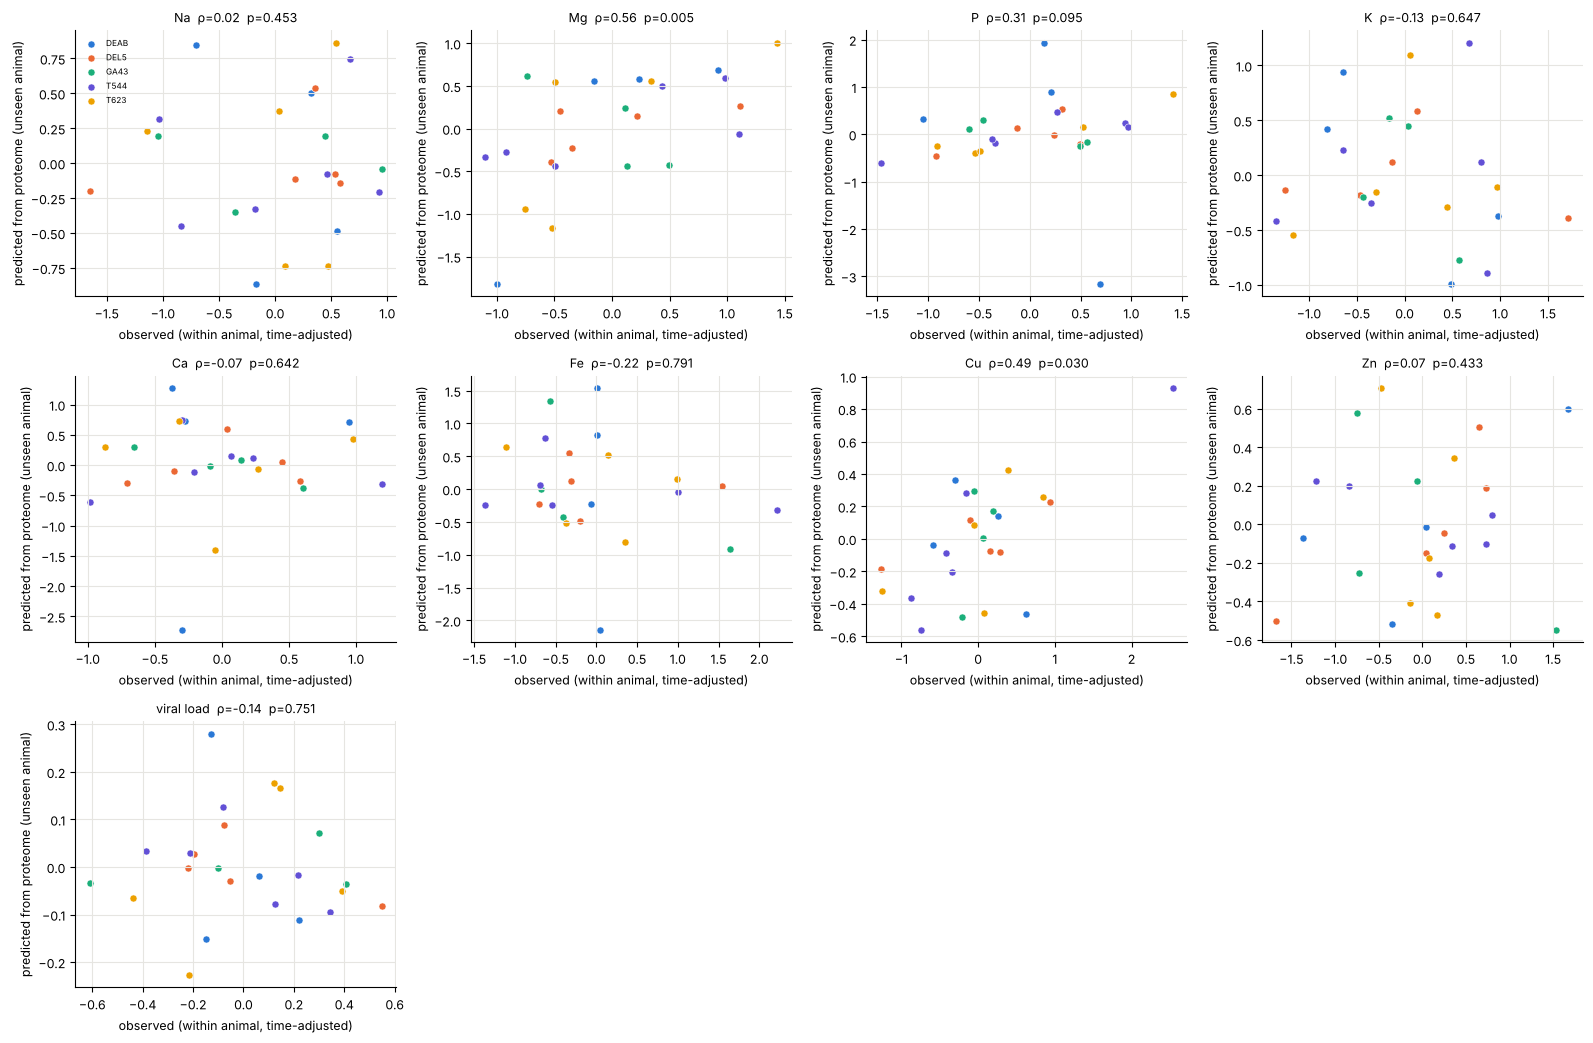

,Spearman (raw),p (raw),Spearman (time-adjusted),p (time-adjusted)
Na,0.379,0.065,0.022,0.453
Mg,0.533,0.015,0.557,0.005
P,0.704,0.010,0.305,0.095
K,0.230,0.159,-0.131,0.647
Ca,0.326,0.149,-0.073,0.642
Fe,-0.223,0.821,-0.222,0.791
Cu,0.671,0.010,0.494,0.030
Zn,0.250,0.234,0.074,0.433
viral load,0.706,0.005,-0.144,0.751


In [9]:
VLN = "viral load"; d[VLN] = d.VL
T2 = loao_grid(ELEMENTS + [VLN], lambda n: d[n].values); T2.to_csv(f"{OUT}/2_leave_one_animal_out_elements.csv")

## 3. Ratios (same analyses)

Cu/Zn: 2s


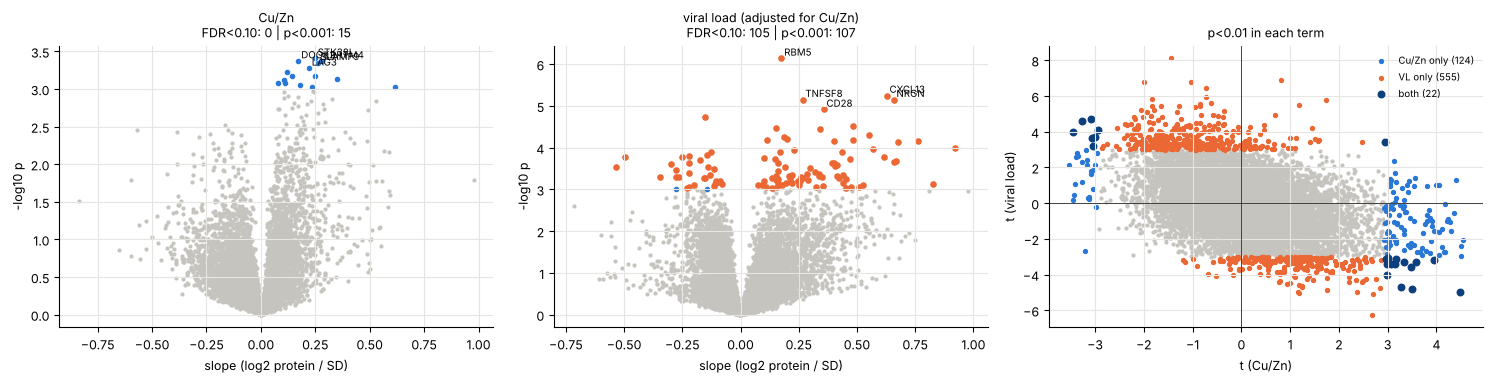

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,0,105,0,0.0
p<0.001,14,106,1,0.1
p<0.01,124,555,22,7.7


Fe/Cu: 2s


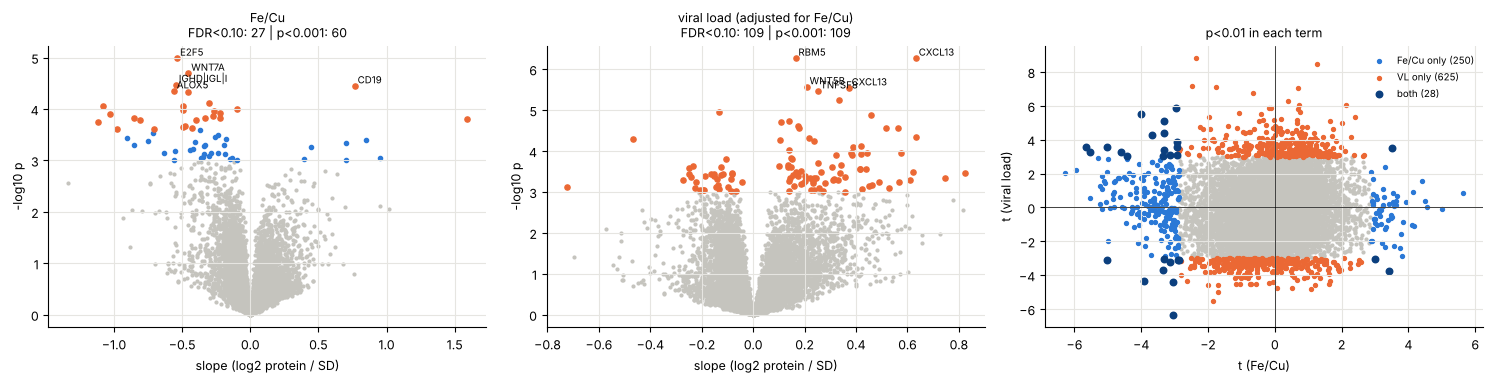

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,27,109,0,0.3
p<0.001,60,109,0,0.6
p<0.01,250,625,28,16.5


Fe/Zn: 2s


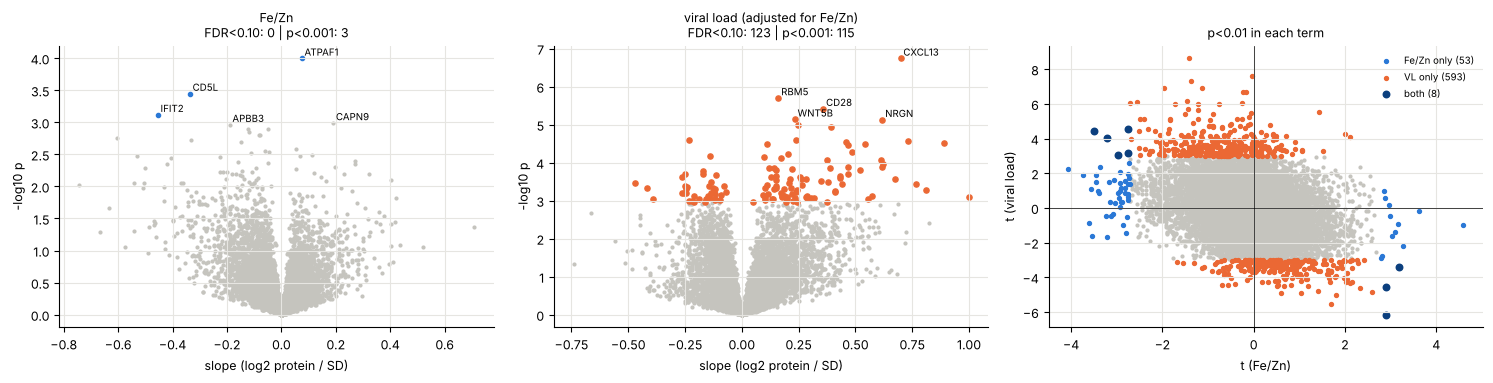

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,0,123,0,0.0
p<0.001,3,115,0,0.0
p<0.01,53,593,8,3.3


Na/K: 2s


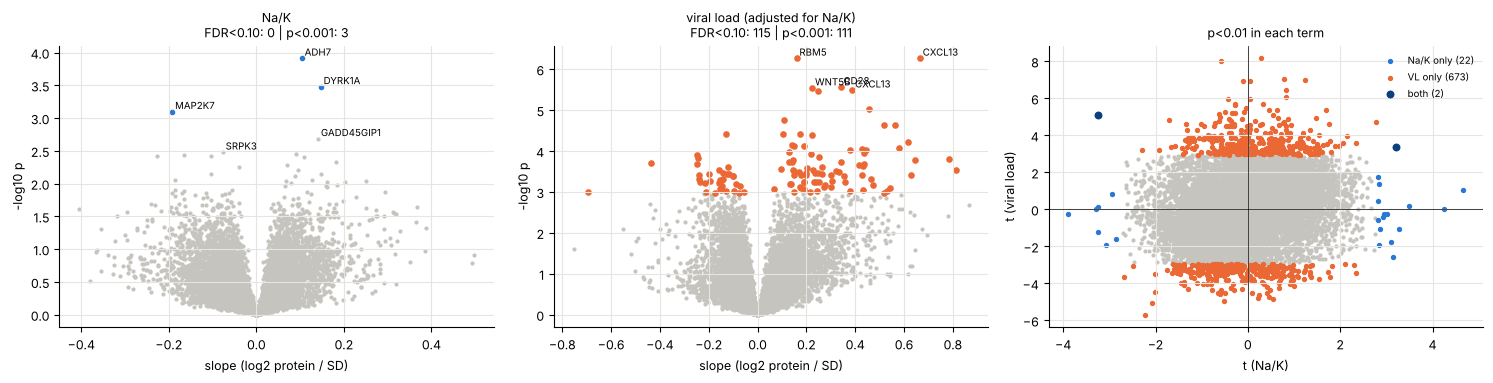

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,0,115,0,0.0
p<0.001,3,111,0,0.0
p<0.01,22,673,2,1.5


Ca/Mg: 2s


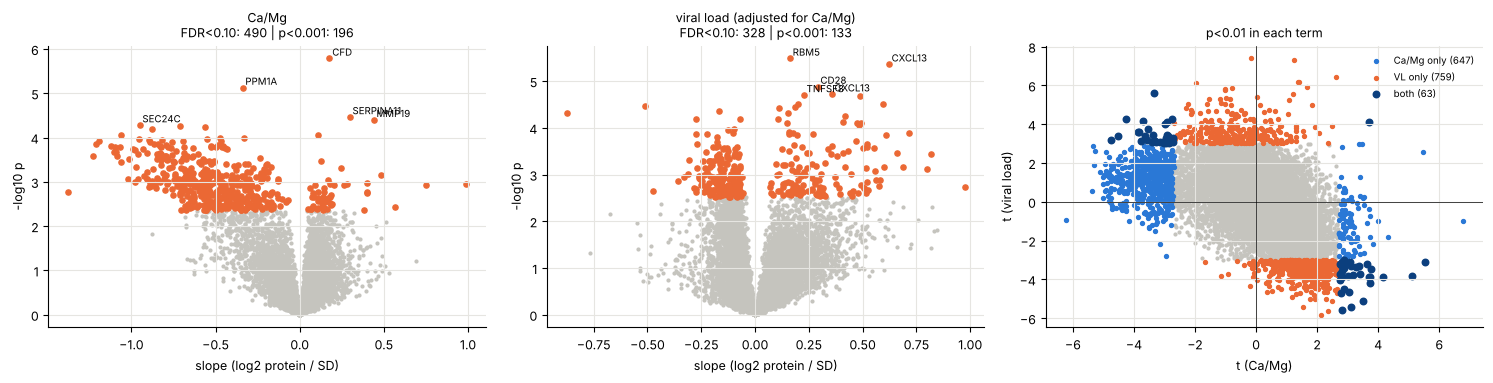

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,474,312,16,14.6
p<0.001,195,132,1,2.4
p<0.01,647,759,63,53.0


Ca/P: 2s


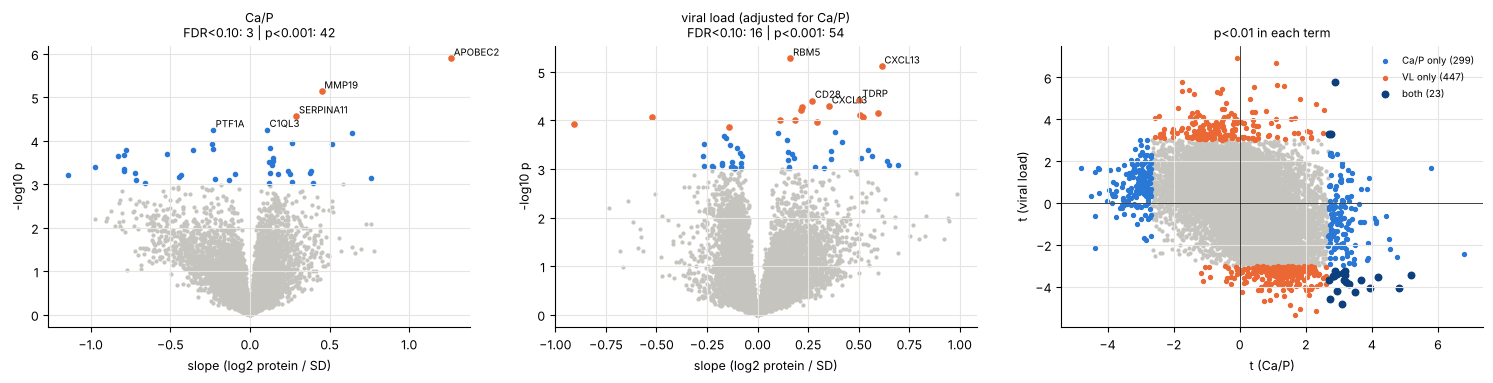

,element only,VL only,both,both expected if independent
threshold,,,,
FDR<0.10,3,16,0,0.0
p<0.001,42,54,0,0.2
p<0.01,299,447,23,13.7


In [10]:
for rt in RATIOS: three_panel(rt)

,FDR<0.10 ratio,FDR<0.10 VL,FDR<0.10 both,p<0.001 ratio,p<0.01 both,p<0.01 both (expected if independent)
ratio,,,,,,
Cu/Zn,0,105,0,15,22,7.7
Fe/Cu,27,109,0,60,28,16.5
Fe/Zn,0,123,0,3,8,3.3
Na/K,0,115,0,3,2,1.5
Ca/Mg,490,328,16,196,63,53.0
Ca/P,3,16,0,42,23,13.7


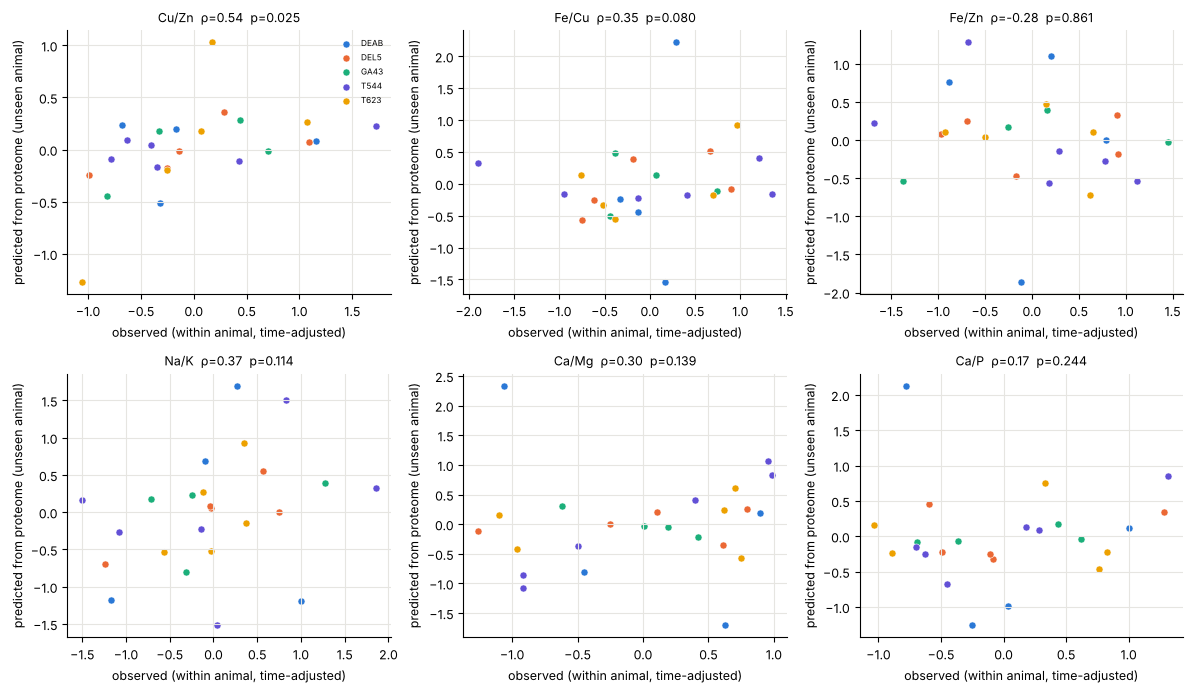

,Spearman (raw),p (raw),Spearman (time-adjusted),p (time-adjusted)
Cu/Zn,0.227,0.209,0.536,0.025
Fe/Cu,0.013,0.443,0.354,0.080
Fe/Zn,-0.033,0.552,-0.276,0.861
Na/K,0.349,0.095,0.368,0.114
Ca/Mg,0.404,0.065,0.302,0.139
Ca/P,0.635,0.010,0.166,0.244


In [11]:
rows = []
for rt in RATIOS:
    r = CACHE[rt][0]; rows.append({"ratio": rt, "FDR<0.10 ratio": int((r.q_E < .1).sum()), "FDR<0.10 VL": int((r.q_VL < .1).sum()), "FDR<0.10 both": int(((r.q_E < .1) & (r.q_VL < .1)).sum()), "p<0.001 ratio": int((r.p_E < .001).sum()), "p<0.01 both": int(((r.p_E < .01) & (r.p_VL < .01)).sum()), "p<0.01 both (expected if independent)": round((r.p_E < .01).sum() * (r.p_VL < .01).sum() / len(r), 1)})
T3 = pd.DataFrame(rows).set_index("ratio"); display(T3); T3.to_csv(f"{OUT}/3_ratio_vs_VL_counts.csv")
T3b = loao_grid(list(RATIOS), lambda n: d[n].values, ncol=3); T3b.to_csv(f"{OUT}/3_leave_one_animal_out_ratios.csv")

## 4. Known proteins only

VL: 1s


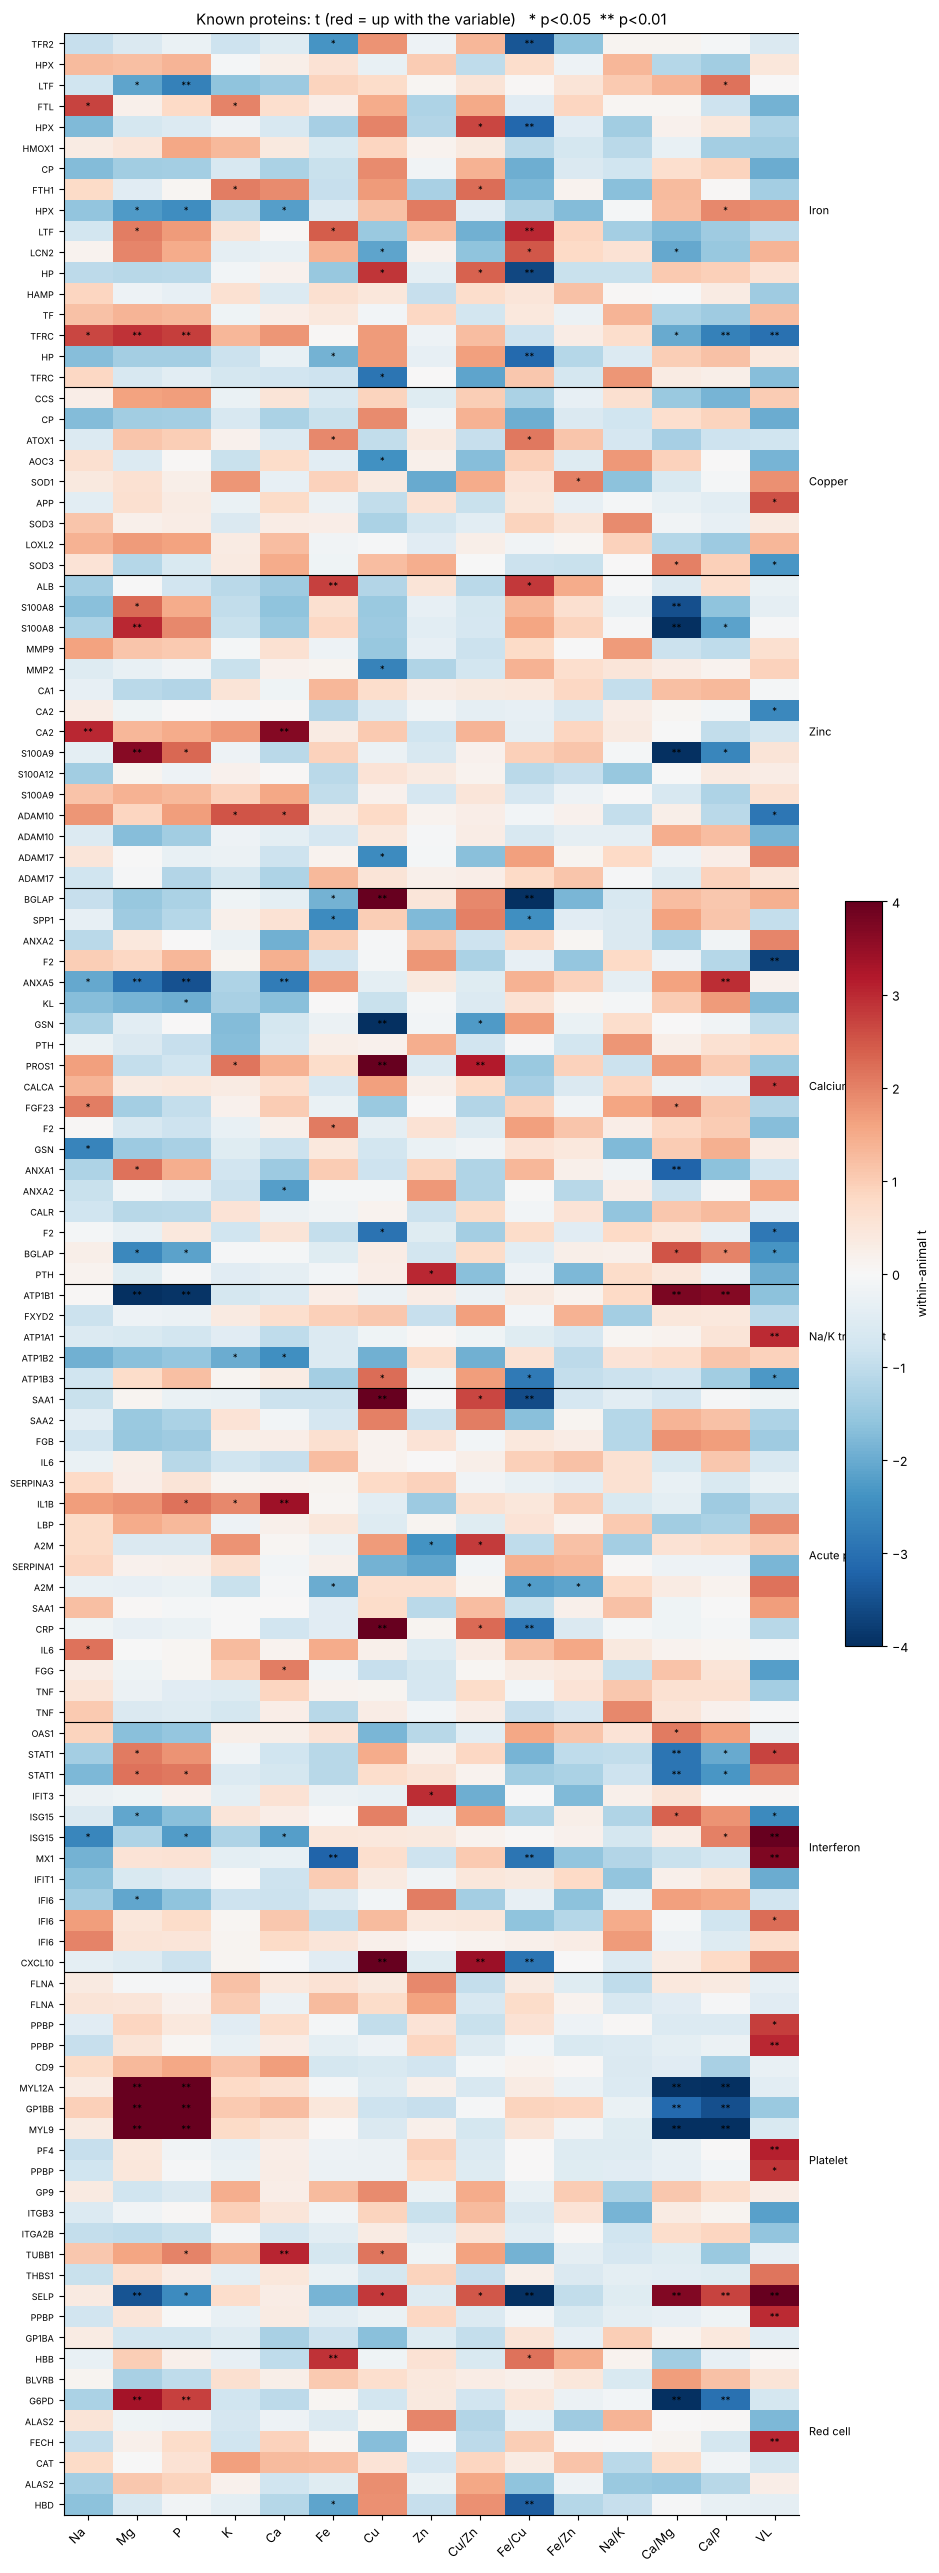

In [12]:
VARS = ELEMENTS + list(RATIOS) + ["VL"]
def tvec(v): r = run(v)[0].set_index("feature"); return r["t_E"], r["p_E"]
rows = []
for g, i in SETS.items():
    for f in W.cols[i]:
        lbl = ann.loc[f, "label"]; row = {"group": g, "protein": lbl, "feature": f}
        for v in VARS: t, p = tvec(v); row[v] = t[f]; row["p_" + v] = p[f]
        rows.append(row)
K = pd.DataFrame(rows); K.to_csv(f"{OUT}/4_known_proteins_t_and_p.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 0.2 * len(K) + 2)); im = ax.imshow(K[VARS].values, cmap="RdBu_r", vmin=-4, vmax=4, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(VARS)), VARS, rotation=45, ha="right"); ax.set_yticks(range(len(K)), [f"{p}" for p in K.protein], fontsize=6.5)
for i, v in enumerate(VARS):
    for j in range(len(K)):
        pv = K.iloc[j]["p_" + v]
        if pv < .05: ax.text(i, j, "*" if pv >= .01 else "**", ha="center", va="center", fontsize=7)
edges = np.r_[0, np.where(K.group.values[1:] != K.group.values[:-1])[0] + 1, len(K)]
for a, b in zip(edges[:-1], edges[1:]): ax.axhline(a - .5, c="k", lw=.8); ax.text(len(VARS) - .3, (a + b) / 2 - .5, K.group.iloc[a], fontsize=8, va="center")
fig.colorbar(im, ax=ax, shrink=.3, label="within-animal t"); ax.set_title("Known proteins: t (red = up with the variable)   * p<0.05  ** p<0.01"); fig.tight_layout(); plt.show()

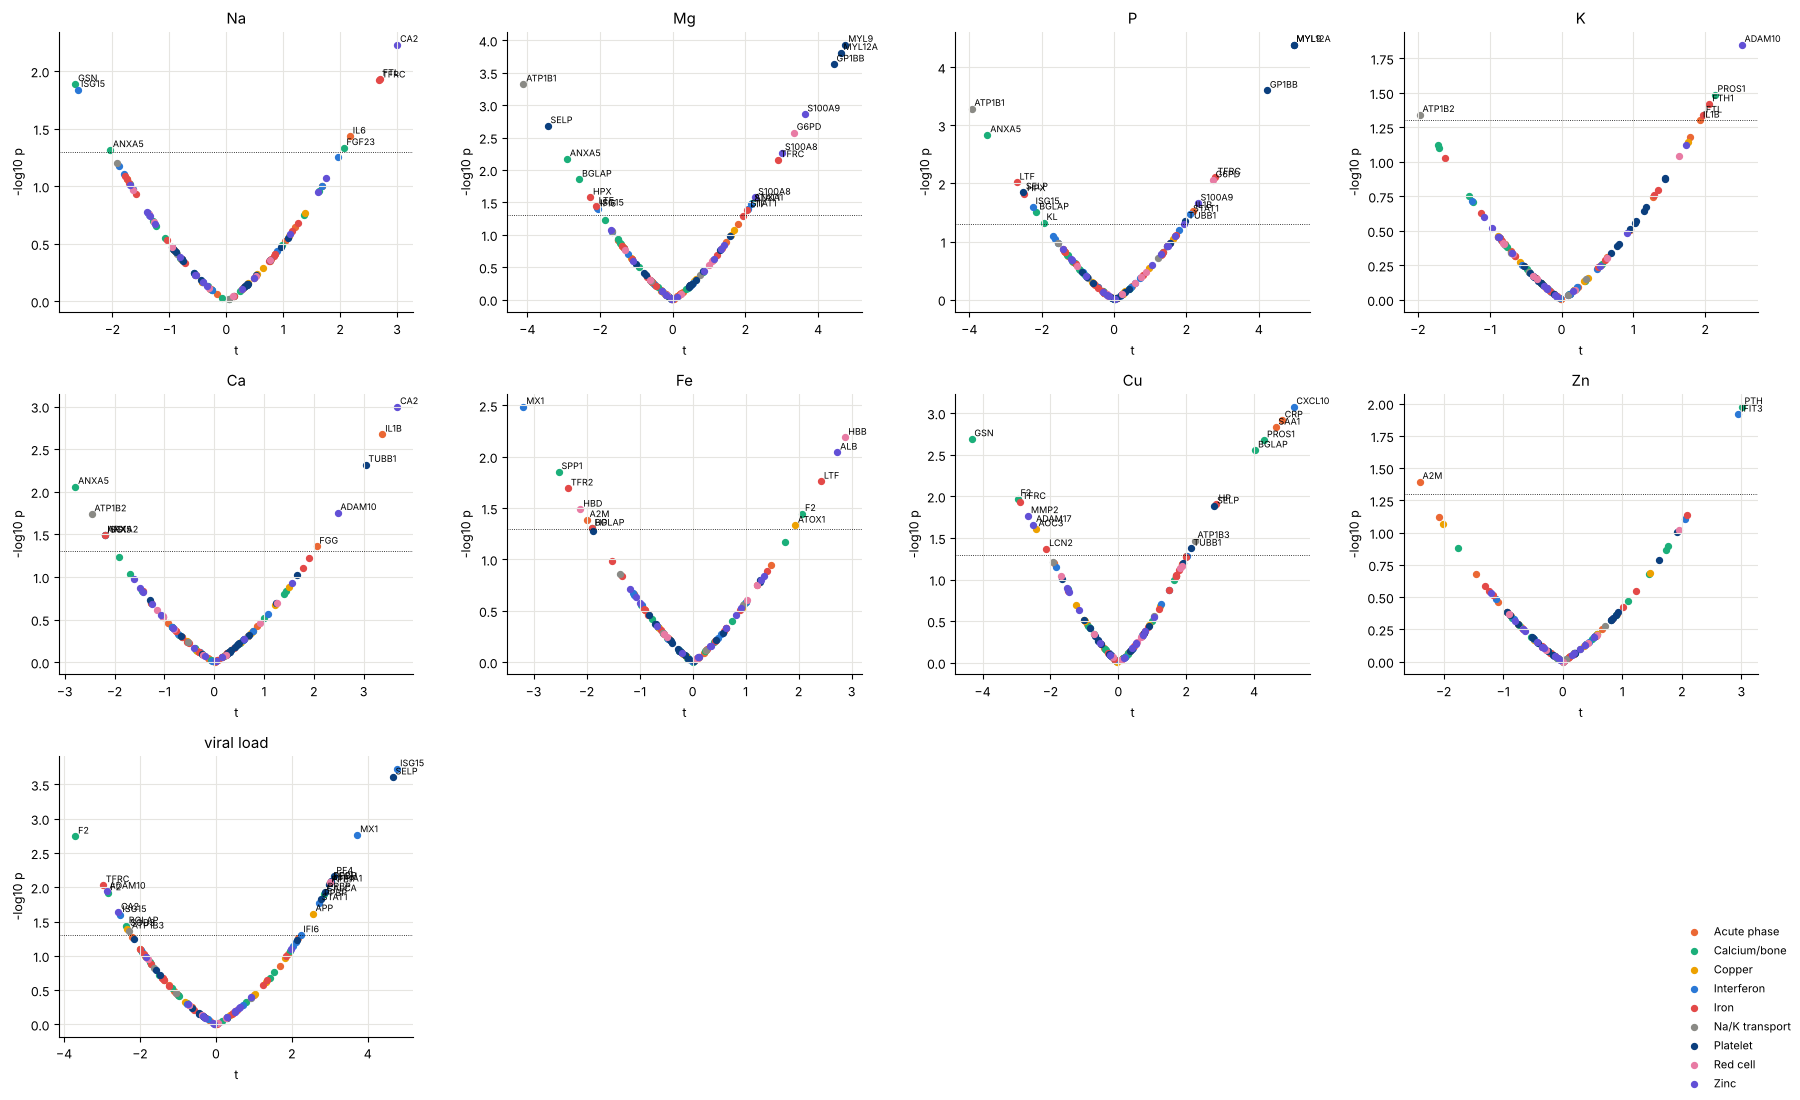

In [13]:
gc = {g: c for g, c in zip(SETS, ["#e34948", "#eda100", "#6250d6", "#1baf7a", "#8a8a85", "#eb6834", "#2a78d6", "#0b3f7e", "#e87ba4"])}
fig, axes = plt.subplots(3, 4, figsize=(18, 11)); axes = axes.ravel()
for ax, v in zip(axes, ELEMENTS + ["VL"]):
    t, p = tvec(v); sub = K[["group", "protein", "feature"]].copy(); sub["x"] = [t[f] for f in sub.feature]; sub["y"] = [-np.log10(p[f]) for f in sub.feature]
    for g, grp in sub.groupby("group"): ax.scatter(grp.x, grp.y, s=18, c=gc[g], label=g)
    for _, r_ in sub[sub.y > -np.log10(.05)].iterrows(): ax.annotate(r_.protein, (r_.x, r_.y), fontsize=6.5, xytext=(2, 2), textcoords="offset points")
    ax.axhline(-np.log10(.05), c="k", lw=.6, ls=":"); ax.set_title(v if v != "VL" else "viral load"); ax.set_xlabel("t"); ax.set_ylabel("-log10 p")
for ax in axes[9:]: ax.axis("off")
h, l = axes[0].get_legend_handles_labels(); fig.legend(h, l, loc="lower right", fontsize=8, frameon=False, ncol=1); fig.tight_layout(); plt.show()

In [14]:
S = pd.DataFrame({v: run(v)[1].set_index("group")["p_set_E"] for v in VARS}); S.index.name = "known group (set test p)"
display(S.round(3).style.background_gradient(cmap="Oranges_r", vmin=0, vmax=.3)); S.to_csv(f"{OUT}/4_known_group_set_tests.csv")

,Na,Mg,P,K,Ca,Fe,Cu,Zn,Cu/Zn,Fe/Cu,Fe/Zn,Na/K,Ca/Mg,Ca/P,VL
known group (set test p),,,,,,,,,,,,,,,
Iron,0.142000,0.074000,0.044000,0.409000,0.387000,0.275000,0.066000,0.715000,0.066000,0.012000,0.691000,0.501000,0.283000,0.086000,0.048000
Copper,0.493000,0.096000,0.166000,0.629000,0.465000,0.491000,0.134000,0.838000,0.573000,0.140000,0.629000,0.283000,0.098000,0.232000,0.026000
Zinc,0.146000,0.038000,0.108000,0.499000,0.010000,0.411000,0.170000,0.992000,0.912000,0.281000,0.820000,0.870000,0.010000,0.120000,0.200000
Calcium/bone,0.126000,0.042000,0.040000,0.525000,0.128000,0.327000,0.004000,0.431000,0.104000,0.020000,0.707000,0.621000,0.044000,0.102000,0.010000
Na/K transport,0.473000,0.018000,0.020000,0.451000,0.240000,0.577000,0.212000,0.904000,0.190000,0.138000,0.457000,0.585000,0.046000,0.038000,0.016000
Acute phase,0.549000,0.683000,0.501000,0.585000,0.230000,0.629000,0.008000,0.683000,0.160000,0.034000,0.565000,0.599000,0.743000,0.639000,0.212000
Interferon,0.038000,0.062000,0.064000,0.956000,0.439000,0.190000,0.068000,0.519000,0.168000,0.054000,0.327000,0.391000,0.032000,0.036000,0.002000
Platelet,0.870000,0.002000,0.004000,0.673000,0.501000,0.800000,0.265000,0.711000,0.457000,0.251000,0.982000,0.754000,0.012000,0.008000,0.002000
Red cell,0.533000,0.150000,0.329000,0.814000,0.697000,0.124000,0.295000,0.641000,0.335000,0.076000,0.585000,0.677000,0.002000,0.230000,0.164000


## 5. Summary

In [15]:
rows = []
for v in ELEMENTS + list(RATIOS):
    r = CACHE[v][0]; l = LOAO[v][True]
    rows.append({"variable": v, "proteins FDR<0.10": int((r.q_E < .1).sum()), "p<0.001 (chance 11)": int((r.p_E < .001).sum()), "VL FDR<0.10 (same model)": int((r.q_VL < .1).sum()),
                 "both p<0.01": int(((r.p_E < .01) & (r.p_VL < .01)).sum()), "both expected": round((r.p_E < .01).sum() * (r.p_VL < .01).sum() / len(r), 1), "unseen-animal Spearman": round(l["r"], 2), "p": round(l["p"], 3)})
SUMM = pd.DataFrame(rows).set_index("variable"); display(SUMM); SUMM.to_csv(f"{OUT}/SUMMARY.csv")
shutil.make_archive("results_elements_proteome", "zip", OUT)
if "google.colab" in sys.modules:
    from google.colab import files; files.download("results_elements_proteome.zip")

,proteins FDR<0.10,p<0.001 (chance 11),VL FDR<0.10 (same model),both p<0.01,both expected,unseen-animal Spearman,p
variable,,,,,,,
Na,0,14,356,27,10.2,0.02,0.453
Mg,3,51,123,29,27.5,0.56,0.005
P,11,53,18,28,18.0,0.31,0.095
K,0,2,172,11,3.3,-0.13,0.647
Ca,0,18,348,49,13.5,-0.07,0.642
Fe,0,5,106,2,3.3,-0.22,0.791
Cu,0,37,169,28,20.0,0.49,0.030
Zn,0,6,146,9,3.4,0.07,0.433
Cu/Zn,0,15,105,22,7.7,0.54,0.025
